# Xception — Hamiltonian Parameter Regression

**Xception** backbone (depthwise-separable convolutions) trained from scratch for regressing
the eight Hamiltonian parameters, with 90° rotation augmentation. Best accuracy-vs-size
trade-off among the evaluated architectures.


In [2]:
!pip install tensorflow scikit-learn pandas matplotlib --quiet
print("✅ Librerías instaladas.")

✅ Librerías instaladas.


In [3]:
import os, gc, time, warnings, random, pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras.applications import Xception
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    GlobalAveragePooling2D, Dense, Input, Dropout, BatchNormalization
)
from tensorflow.keras import regularizers
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

warnings.filterwarnings('ignore')

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

gpus = tf.config.list_physical_devices('GPU')
for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)

tf.keras.mixed_precision.set_global_policy('mixed_float16')

param_names = ["T", "Jex2", "Jex3", "Jex4", "Kan1", "KanS", "Hex", "KDM"]
param_labels = {
    "T": r"$T^{(0)}$", "Jex2": r"$\tilde{J}_2$", "Jex3": r"$\tilde{J}_3$",
    "Jex4": r"$\tilde{J}_4$", "Kan1": r"$\tilde{K}_{an1}$", "KanS": r"$\tilde{K}_{anS}$",
    "Hex": r"$\tilde{H}_{ex}$", "KDM": r"$\tilde{K}_{DM}$",
}
N_PARAMS = 8
T_IDX = 0
identificables = ["T", "Jex2", "Kan1", "KanS", "Hex", "KDM"]

print(f"TF: {tf.__version__} | GPUs: {len(gpus)} | Policy: {tf.keras.mixed_precision.global_policy().name}")

2026-07-05 23:01:32.454457: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-07-05 23:01:32.527791: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-07-05 23:01:34.059616: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TF: 2.20.0 | GPUs: 1 | Policy: mixed_float16


In [4]:
DATASET_PATH = "/workspace/Preprocess/latent_space_outputs/dataset_final_estructuras.npz"

data = np.load(DATASET_PATH, allow_pickle=True)
X = np.copy(data['img']).astype(np.float32)
y = np.copy(data['params']).astype(np.float32)

print(f"X: {X.shape} | y: {y.shape} | rango X: [{X.min():.3f}, {X.max():.3f}]")

X: (166141, 39, 39, 1) | y: (166141, 8) | rango X: [-1.000, 1.000]


In [5]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.15, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.1765, random_state=SEED)

scaler = MinMaxScaler()
y_train_scaled = scaler.fit_transform(y_train)
y_val_scaled   = scaler.transform(y_val)
y_test_scaled  = scaler.transform(y_test)
data_range = scaler.data_max_ - scaler.data_min_

print(f"Train: {X_train.shape[0]:,} | Val: {X_val.shape[0]:,} | Test: {X_test.shape[0]:,}")

Train: 116,293 | Val: 24,926 | Test: 24,922


In [6]:
BATCH_SIZE = 256

def make_ds(X_, y_, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((X_, y_))
    if shuffle:
        ds = ds.shuffle(10000, seed=SEED)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

train_ds = make_ds(X_train, y_train_scaled, shuffle=True)
val_ds   = make_ds(X_val,   y_val_scaled)
test_ds  = make_ds(X_test,  y_test_scaled)

for xb, yb in train_ds.take(1):
    print(f"x: {xb.shape}  y: {yb.shape}")
print("✅ Pipeline mínimo — augment/resize/RGB corren en GPU dentro del modelo")

I0000 00:00:1783292508.388290  288619 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 96579 MB memory:  -> device: 0, name: NVIDIA H200, pci bus id: 0000:5d:00.0, compute capability: 9.0


x: (256, 39, 39, 1)  y: (256, 8)
✅ Pipeline mínimo — augment/resize/RGB corren en GPU dentro del modelo


2026-07-05 23:01:50.750644: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


In [7]:
class PhysicalAugmentation(tf.keras.layers.Layer):
    """Rotaciones 90° + flips aleatorios a nivel de batch, en GPU.
    Solo activa en entrenamiento. Los parámetros físicos son invariantes
    bajo estas transformaciones (isotropía del Hamiltoniano)."""
    def call(self, x, training=None):
        if not training:
            return x
        k = tf.random.uniform([], minval=0, maxval=4, dtype=tf.int32)
        x = tf.image.rot90(x, k=k)
        x = tf.cond(tf.random.uniform([]) > 0.5,
                    lambda: tf.image.flip_left_right(x), lambda: x)
        x = tf.cond(tf.random.uniform([]) > 0.5,
                    lambda: tf.image.flip_up_down(x), lambda: x)
        return x

    def get_config(self):
        return super().get_config()


def build_xception_aug_scratch(n_params=8):
    backbone = Xception(include_top=False,
                        weights=None,                 # <-- SIN ImageNet
                        input_shape=(224, 224, 3))
    backbone.trainable = True

    inputs = Input(shape=(39, 39, 1))                 # entrada nativa 39×39
    x = PhysicalAugmentation()(inputs)                # augment EN GPU (solo training)
    x = tf.keras.layers.Resizing(224, 224)(x)         # resize EN GPU
    x = tf.keras.layers.Concatenate()([x, x, x])      # grayscale->RGB EN GPU
    x = backbone(x)
    x = GlobalAveragePooling2D()(x)
    x = BatchNormalization()(x)
    x = Dropout(0.4)(x)
    x = Dense(256, activation='relu',
              kernel_regularizer=regularizers.l2(1e-4))(x)
    x = BatchNormalization()(x)
    x = Dropout(0.3)(x)
    outputs = Dense(n_params, activation='linear', dtype='float32')(x)

    return Model(inputs, outputs, name="Xception_aug_scratch_noweights")

model = build_xception_aug_scratch()
print(f"Parámetros totales: {model.count_params():,}  (inicializados aleatoriamente)")

Parámetros totales: 21,397,296  (inicializados aleatoriamente)


In [8]:
# Desde cero conviene un LR mayor que en fine-tuning (3e-4 en vez de 1e-4)
model.compile(optimizer=Adam(3e-4), loss='mse', metrics=['mae'])
print("✅ Compilado — Xception desde cero, MSE, sin sample weights.")

✅ Compilado — Xception desde cero, MSE, sin sample weights.


In [9]:
EPOCHS = 60   # desde cero converge más lento que fine-tuning

early_stop = EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)
reduce_lr  = ReduceLROnPlateau(monitor='val_loss', factor=0.3, patience=7, min_lr=1e-7)

t0 = time.time()
history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS,
                    callbacks=[early_stop, reduce_lr], verbose=1)
total_time = time.time() - t0
print(f"\n⏱ {total_time/60:.1f} min | Épocas: {len(history.history['loss'])} "
      f"| {total_time/len(history.history['loss']):.1f}s/época")

Epoch 1/60


2026-07-05 23:03:30.537041: I external/local_xla/xla/service/service.cc:163] XLA service 0x73f47c02c470 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
2026-07-05 23:03:30.537090: I external/local_xla/xla/service/service.cc:171]   StreamExecutor device (0): NVIDIA H200, Compute Capability 9.0
2026-07-05 23:03:30.921498: W tensorflow/compiler/tf2xla/kernels/random_ops.cc:108] Warning: Using tf.random.uniform with XLA compilation will ignore seeds; consider using tf.random.stateless_uniform instead if reproducible behavior is desired. Xception_aug_scratch_noweights_1/physical_augmentation_1/random_uniform
2026-07-05 23:03:30.921712: W tensorflow/compiler/tf2xla/kernels/random_ops.cc:62] Warning: Using tf.random.uniform with XLA compilation will ignore seeds; consider using tf.random.stateless_uniform instead if reproducible behavior is desired. Xception_aug_scratch_noweights_1/physical_augmentation_1/random_uniform_1/RandomUniform
2026-07-05 23:03:

454/455 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step - loss: 0.7444 - mae: 0.5393

2026-07-05 23:06:35.709210: W tensorflow/compiler/tf2xla/kernels/assert_op.cc:39] Ignoring Assert operator Xception_aug_scratch_noweights_1/physical_augmentation_1/rot90/Assert/AssertGuard/Assert
2026-07-05 23:06:41.782965: I external/local_xla/xla/service/gpu/autotuning/dot_search_space.cc:208] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
2026-07-05 23:06:53.942347: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-07-05 23:06:54.057609: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-07-05 23:

455/455 ━━━━━━━━━━━━━━━━━━━━ 0s 309ms/step - loss: 0.7443 - mae: 0.5392

2026-07-05 23:08:54.184874: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-07-05 23:08:54.300737: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-07-05 23:08:56.712285: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-07-05 23:08:56.823221: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-07-05 23:08:58.797688: E external/local_xla/xla/stream_

455/455 ━━━━━━━━━━━━━━━━━━━━ 358s 421ms/step - loss: 0.7443 - mae: 0.5392 - val_loss: 0.1108 - val_mae: 0.1556 - learning_rate: 3.0000e-04
Epoch 2/60
455/455 ━━━━━━━━━━━━━━━━━━━━ 35s 76ms/step - loss: 0.3194 - mae: 0.2843 - val_loss: 0.0660 - val_mae: 0.0830 - learning_rate: 3.0000e-04
Epoch 3/60
455/455 ━━━━━━━━━━━━━━━━━━━━ 35s 76ms/step - loss: 0.1862 - mae: 0.1821 - val_loss: 0.0653 - val_mae: 0.0795 - learning_rate: 3.0000e-04
Epoch 4/60
455/455 ━━━━━━━━━━━━━━━━━━━━ 35s 76ms/step - loss: 0.1217 - mae: 0.1234 - val_loss: 0.0774 - val_mae: 0.1119 - learning_rate: 3.0000e-04
Epoch 5/60
455/455 ━━━━━━━━━━━━━━━━━━━━ 35s 76ms/step - loss: 0.0904 - mae: 0.0995 - val_loss: 0.0486 - val_mae: 0.0602 - learning_rate: 3.0000e-04
Epoch 6/60
455/455 ━━━━━━━━━━━━━━━━━━━━ 35s 76ms/step - loss: 0.0698 - mae: 0.0824 - val_loss: 0.0471 - val_mae: 0.0621 - learning_rate: 3.0000e-04
Epoch 7/60
455/455 ━━━━━━━━━━━━━━━━━━━━ 35s 76ms/step - loss: 0.0555 - mae: 0.0743 - val_loss: 0.0423 - val_mae: 0.0617 -

In [10]:
y_pred = scaler.inverse_transform(model.predict(test_ds, verbose=0))
y_true = y_test.copy()

rows = []
for i, name in enumerate(param_names):
    rows.append({"Parameter": name,
                 "MAE": round(mean_absolute_error(y_true[:, i], y_pred[:, i]), 4),
                 "RMSE": round(np.sqrt(mean_squared_error(y_true[:, i], y_pred[:, i])), 4),
                 "R²": round(r2_score(y_true[:, i], y_pred[:, i]), 4)})
df_m = pd.DataFrame(rows).set_index("Parameter").sort_values("R²", ascending=False)
print(df_m.to_string())

print(f"\nR² promedio (todos):          {df_m['R²'].mean():.4f}")
print(f"R² promedio (identificables): {df_m.loc[identificables, 'R²'].mean():.4f}")

2026-07-05 23:37:11.130376: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-07-05 23:37:11.245992: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-07-05 23:37:13.775964: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-07-05 23:37:13.886880: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-07-05 23:37:15.868173: E external/local_xla/xla/stream_

              MAE    RMSE      R²
Parameter                        
KDM        0.0194  0.0290  0.9942
Hex        0.0125  0.0191  0.9612
T          0.3435  0.6306  0.9596
Kan1       0.0515  0.0803  0.9427
Jex2       0.0184  0.0465  0.8908
KanS       0.0272  0.0372  0.6434
Jex3       0.0295  0.0729  0.0065
Jex4       0.0223  0.0577  0.0017

R² promedio (todos):          0.6750
R² promedio (identificables): 0.8986


In [11]:
X_test_rot = np.rot90(X_test, k=1, axes=(1, 2)).copy()

y_pred_rot = scaler.inverse_transform(model.predict(
    tf.data.Dataset.from_tensor_slices(X_test_rot).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE),
    verbose=0))

nmad = (np.abs(y_pred - y_pred_rot) / data_range).mean()
r2_rot_ident = np.mean([r2_score(y_true[:, param_names.index(p)],
                                 y_pred_rot[:, param_names.index(p)])
                        for p in identificables])

print(f"nMAD rotación:              {nmad:.4f}  (menor = más invariante)")
print(f"R² ident. sobre rotadas:    {r2_rot_ident:.4f}")
print(f"R² ident. sobre originales: {df_m.loc[identificables, 'R²'].mean():.4f}")

nMAD rotación:              0.0123  (menor = más invariante)
R² ident. sobre rotadas:    0.8980
R² ident. sobre originales: 0.8986


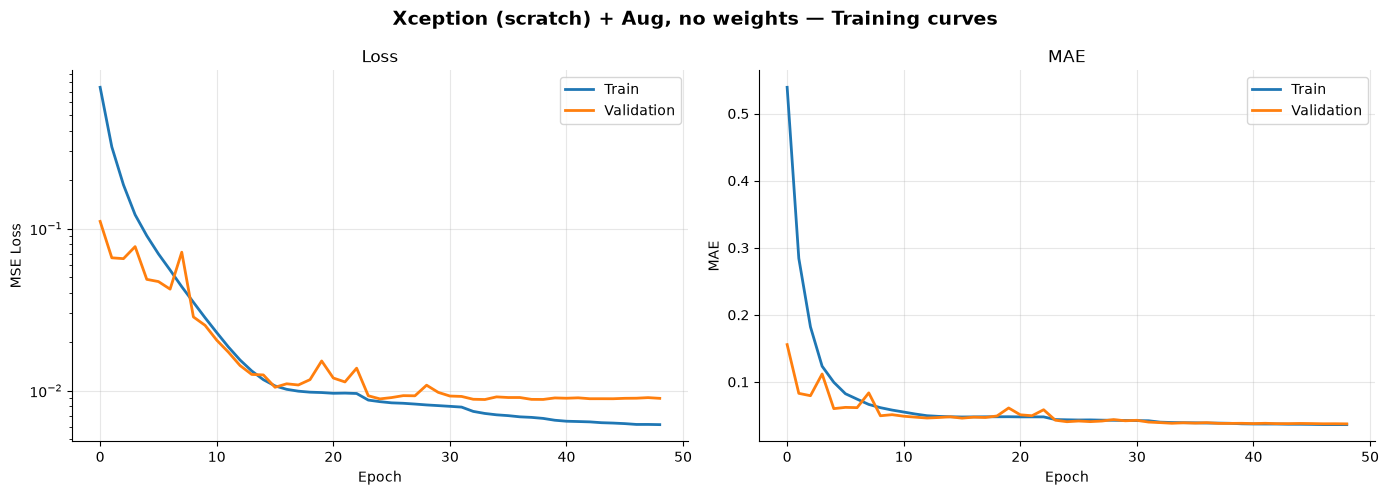

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), facecolor="white")

axes[0].plot(history.history['loss'], label='Train', linewidth=2)
axes[0].plot(history.history['val_loss'], label='Validation', linewidth=2)
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("MSE Loss")
axes[0].set_yscale('log')
axes[0].set_title("Loss"); axes[0].legend(); axes[0].grid(alpha=0.3)
axes[0].spines[["top","right"]].set_visible(False)

axes[1].plot(history.history['mae'], label='Train', linewidth=2)
axes[1].plot(history.history['val_mae'], label='Validation', linewidth=2)
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("MAE")
axes[1].set_title("MAE"); axes[1].legend(); axes[1].grid(alpha=0.3)
axes[1].spines[["top","right"]].set_visible(False)

plt.suptitle("Xception (scratch) + Aug, no weights — Training curves",
             fontsize=14, fontweight="bold")
plt.tight_layout()
OUT_DIR = "/workspace/Process/Images"
os.makedirs(OUT_DIR, exist_ok=True)
plt.savefig(f"{OUT_DIR}/xception_aug_scratch_noweights_curves.pdf",
            bbox_inches="tight", facecolor="white")
plt.show()

In [13]:
SAVE_DIR = "/workspace/Models/Inverse/ModelWeights"
os.makedirs(SAVE_DIR, exist_ok=True)
os.makedirs("/workspace/Process/metrics", exist_ok=True)

model.save(f"{SAVE_DIR}/modelo_xception_aug_scratch_noweights_estructuras.keras")
with open(f"{SAVE_DIR}/scaler_xception_aug_scratch_noweights.pkl", 'wb') as f:
    pickle.dump(scaler, f)
np.savez("/workspace/Process/xception_aug_scratch_noweights_resultados.npz",
         y_true=y_true, y_pred=y_pred, y_pred_rot=y_pred_rot,
         loss=history.history['loss'], val_loss=history.history['val_loss'])
df_m.to_csv("/workspace/Process/metrics/xception_aug_scratch_noweights_metrics.csv")
print(f"✅ Guardado: {SAVE_DIR}/modelo_xception_aug_scratch_noweights_estructuras.keras")

✅ Guardado: /workspace/Models/Inverse/ModelWeights/modelo_xception_aug_scratch_noweights_estructuras.keras
